In [1]:
import numpy as np
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.wcs import WCS
import matplotlib.pyplot as plt

fits_f187n = '/home/roberto/MAST_2026-07-31T01_03_53.583Z/MAST_2026-08-14T16_49_24.413Z/JWST/jw02729-o001_t001_nircam_clear-f187n_i2d.fits'
fits_f200w = '/home/roberto/MAST_2026-07-31T01_03_53.583Z/MAST_2026-08-27T18_26_07.310Z/JWST/jw02729-o001_t001_nircam_clear-f200w_i2d.fits'

with fits.open(fits_f187n) as hdul_187, fits.open(fits_f200w) as hdul_200:
    data_187 = hdul_187['SCI',1].data
    header_187 = hdul_187['SCI',1].header
    wcs_187 = WCS(header_187)
    
    data_200 = hdul_200['SCI',1].data
    header_200 = hdul_200['SCI',1].header
    wcs_200 = WCS(header_200)

Set DATE-AVG to '2022-06-03T00:38:36.813' from MJD-AVG.
Set DATE-END to '2022-06-03T03:29:02.366' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.382178 from OBSGEO-[XYZ].
Set OBSGEO-H to 1651545788.871 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T01:43:50.399' from MJD-AVG.
Set DATE-END to '2022-06-03T04:30:46.618' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.399982 from OBSGEO-[XYZ].
Set OBSGEO-H to 1651812827.954 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [2]:
print(data_187.shape)
print(data_200.shape)

(8539, 14336)
(8545, 14339)


In [7]:
import pyregion
from astropy import units as u
from astropy import constants as cte 
import regions
from astropy.coordinates import Angle
from astropy.table import QTable, Table
from astropy.coordinates import SkyCoord
import cmasher as cm

In [4]:
'''Primero cargamos las ubicacionees de los globules'''
regs = regions.Regions.read('/home/roberto/MAST_2026-07-31T01_03_53.583Z/R_p_01.reg', format="ds9")
regs = [_ for _ in regs if hasattr(_, 'center') and _.visual.get('marker') == "o"]
len(regs)

2

In [5]:
source_table = QTable(
    [
        {"ICRS": r.center, "Isolated": r.visual.get('markeredgewidth') == 3} 
        for r in regs
    ]
)
c0 = source_table[1]['ICRS']
source_table["PA"] = c0.position_angle(source_table["ICRS"]).to(u.deg)
source_table["Sep"] = source_table["ICRS"].separation(c0).to(u.arcsec)
source_table["PA"].info.format = ".2f"
source_table["Sep"].info.format = ".2f"

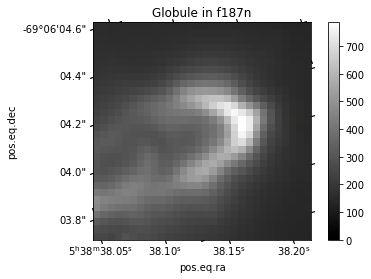

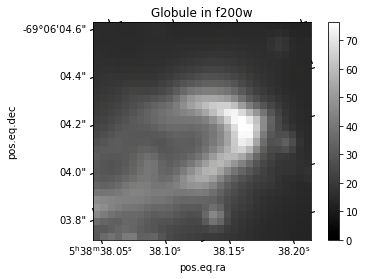

In [8]:
j1, i1 = wcs_187.world_to_array_index(source_table[0]['ICRS'])
size = 15
yslice, xslice = slice(j1 - size, j1 + size), slice(i1 - size, i1 + size)
cutout = data_187[yslice, xslice]
wcutout = wcs_187.slice((yslice, xslice))
j1_, i1_ = wcs_200.world_to_array_index(source_table[0]['ICRS'])
yslice_, xslice_ = slice(j1_ - size, j1_ + size), slice(i1_ - size, i1_ + size)
cutout_ = data_200[yslice_, xslice_]
wcutout_ = wcs_200.slice((yslice_, xslice_))


fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
im = ax.imshow(cutout, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)
ax.set_title("Globule in f187n")
...;
fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
im = ax.imshow(cutout_, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)
ax.set_title(f"Globule in f200w")
...;

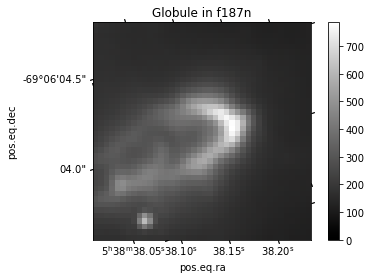

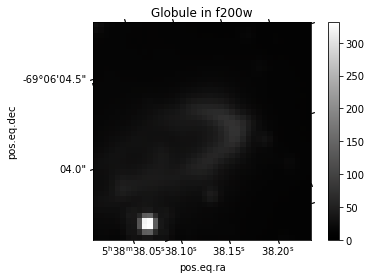

In [9]:
j1, i1 = wcs_187.world_to_array_index(source_table[0]['ICRS'])
size = 20
yslice, xslice = slice(j1 - size, j1 + size), slice(i1 - size, i1 + size)
cutout = data_187[yslice, xslice]
wcutout = wcs_187.slice((yslice, xslice))
j1_, i1_ = wcs_200.world_to_array_index(source_table[0]['ICRS'])
yslice_, xslice_ = slice(j1_ - size, j1_ + size), slice(i1_ - size, i1_ + size)
cutout_ = data_200[yslice_, xslice_]
wcutout_ = wcs_200.slice((yslice_, xslice_))


fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
im = ax.imshow(cutout, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)
ax.set_title("Globule in f187n")
...;
fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
im = ax.imshow(cutout_, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)
ax.set_title(f"Globule in f200w")
...;

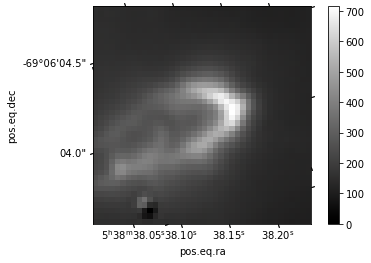

In [10]:
fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
nuevo = 1.01*((cutout-1.68)-(cutout_-0.38))
im = ax.imshow(nuevo, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)
...;

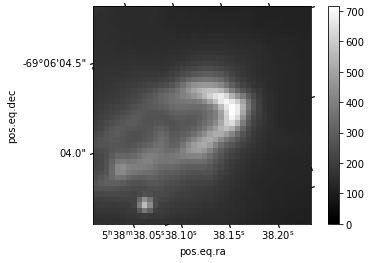

In [11]:
fig = plt.figure()
ax = fig.add_subplot(projection=wcutout)
im = ax.imshow(0.91*cutout, vmin=0.0, cmap=cm.neutral)
cb = fig.colorbar(im, ax=ax)

In [84]:
'''Aqui mostramos como se deberiain de ver'''
filter_ = fits.open('/home/roberto/MAST_2026-07-31T01_03_53.583Z/MAST_2026-08-14T16_49_24.413Z/JWST/jw02729-o001_t001_nircam_clear-f187n_i2d.fits')
hdu = filter_['SCI']
wcs = WCS(hdu)
'''Aqui mostramos como se deberiain de ver'''
filter_200 = fits.open('/home/roberto/MAST_2026-07-31T01_03_53.583Z/MAST_2026-08-27T18_26_07.310Z/JWST/jw02729-o001_t001_nircam_clear-f200w_i2d.fits')
hdu_200 = filter_200['SCI']
wcs_200 = WCS(hdu_200)

Set DATE-AVG to '2022-06-03T00:38:36.813' from MJD-AVG.
Set DATE-END to '2022-06-03T03:29:02.366' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.382178 from OBSGEO-[XYZ].
Set OBSGEO-H to 1651545788.871 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T01:43:50.399' from MJD-AVG.
Set DATE-END to '2022-06-03T04:30:46.618' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.399982 from OBSGEO-[XYZ].
Set OBSGEO-H to 1651812827.954 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [83]:
class CUT_test:
    def __init__(self,pdata,hdu,hdu1,data,size):
        self.center = pdata["ICRS"]
        # PA of source wrt star
        self.pa_source = pdata["PA"]
        # and PA of star wrt source
        self.pa_star = Angle(self.pa_source + 180 * u.deg).wrap_at(360 * u.deg)
        self.size = size
        #Para nueva mascara de estrellas con f200w
        data_187, data_200 = data
        #new_data = 1.01*((data_187-1.68)-(data_200-0.38))
        #self.cutout
        self.cutout_187 = Cutout2D(
                data_187, position=self.center, size=size, wcs=WCS(hdu), copy=True,
            )
        self.cutout_200 = Cutout2D(
                data_200, position=self.center, size=size, wcs=WCS(hdu1), copy=True,
            )
        self.image = 1.01*((self.cutout_187.data-1.68)-(self.cutout_200.data-0.38))
        #self.cutout = Cutout2D(
        #        new_data, position=self.center, size=size, wcs=WCS(hdu), copy=True,
        #    )
            
        #self.image = self.cutout.data
        self.wcs = self.cutout_187.wcs
        ny, nx = self.image.shape
        self.x, self.y = np.meshgrid(np.arange(nx), np.arange(ny))
        self.image_coords = self.wcs.pixel_to_world(self.x, self.y)
        #self.cero = self.image[self.cutout.mask][0]
        # Radius and PA of each pixel with respect to the NOMINAL center
        self.r = self.center.separation(self.image_coords)
        self.pa = self.center.position_angle(self.image_coords)
        # Default mask has max radius of half the cutout size
        self.set_mask(r_out=self.size / 2)
        
        self.find_bary_center()
        # Recalculate r, pa, and masks wrt the barycenter
        #self.r = self.barycenter.separation(self.image_coords)
        #self.pa = self.barycenter.position_angle(self.image_coords)
        #nuevo
        self.refined_center, self.center_offset, self.type_model = self.refine_center_symmetry(
            search_range=5, radio_analisis=8, modelo='auto'
        )
        self.r = self.refined_center.separation(self.image_coords)
        self.pa = self.refined_center.position_angle(self.image_coords)
        #termina nuevo
        self.set_mask(r_out=self.size / 2)
        self.bright_bg = np.percentile(
            self.image[self.mask],
            10,
        )
        
    def set_mask(
        self,
        r_out = 0.5 * u.arcsec,
        r_in = 0.1 * u.arcsec,
        r_core = 0.15 * u.arcsec,
        mu_min = 0.9,
    ):
        cth = np.cos((self.pa - self.pa_star))
        self.mask = (self.r <= r_out) & ((cth >= mu_min) | (self.r <= r_in))
        #self.mask = (self.r <= r_out)  | (self.r <= r_in)
        self.coremask = (self.r <= r_in)
        self.mask_stars = self.cutout_200.data < 100
    def find_bary_center(self):
        """Refine estimate of center by using flux-weighted mean
        position within the core mask
        """
        m = (self.coremask)

        # Original version was flux-weighted mean
        xbary = np.average(self.x[m], weights=self.image[m])
        ybary = np.average(self.x[m], weights=self.image[m])
        
        self.barycenter = self.wcs.pixel_to_world(xbary, ybary)
        
    def refine_center_symmetry(self, search_range=5, radio_analisis=8, modelo='auto'):
        """
        To find the new and correct center in the globule
    
        Parameters:
        - search_range: pixs on the axis.
        - radio_analisis: to stimate the residues.
        - modelo: 'circular', 'parabolica', o 'auto' (prueba ambos).
    
        Retorna:
        - THe new center in SkyCoord
        - teh best offset in axis.
        - the type of the model.
        """
        centro_actual = self.barycenter
        centro_sky = self.barycenter
    
        ref_point = centro_sky.directional_offset_by(
            self.pa_star, 1.0 * u.arcsec
        )
    
        x0, y0 = self.wcs.world_to_pixel(centro_sky)
        x1, y1 = self.wcs.world_to_pixel(ref_point)
    
        dx = x1 - x0
        dy = y1 - y0
        norm = np.sqrt(dx**2 + dy**2)
        eje_x = dx / norm
        eje_y = dy / norm
    
        perp_x = -eje_y
        perp_y = eje_x
    
        def _residuo_simetria(offset, modelo_local):
            xc = x0 + offset * eje_x
            yc = y0 + offset * eje_y
        
            residuo = 0.0
            n_pixeles = 0
        
            for d_eje in range(-radio_analisis, radio_analisis + 1):
                for d_perp in range(-radio_analisis, radio_analisis + 1):
                    x_pix = xc + d_eje * eje_x + d_perp * perp_x
                    y_pix = yc + d_eje * eje_y + d_perp * perp_y
                
                    x_sim = xc + d_eje * eje_x - d_perp * perp_x
                    y_sim = yc + d_eje * eje_y - d_perp * perp_y
                
                    if modelo_local == 'parabolica':
                        if abs(d_eje) > 0:
                            factor = 1.0 / np.sqrt(abs(d_eje))
                            x_pix = xc + d_eje * eje_x + (d_perp * factor) * perp_x
                            y_pix = yc + d_eje * eje_y + (d_perp * factor) * perp_y
                            x_sim = xc + d_eje * eje_x - (d_perp * factor) * perp_x
                            y_sim = yc + d_eje * eje_y - (d_perp * factor) * perp_y
                
                    ix, iy = int(round(x_pix)), int(round(y_pix))
                    ix_sim, iy_sim = int(round(x_sim)), int(round(y_sim))
                
                    if (0 <= ix < self.image.shape[1] and 
                        0 <= iy < self.image.shape[0] and
                        0 <= ix_sim < self.image.shape[1] and 
                        0 <= iy_sim < self.image.shape[0]):
                    
                        if not self.mask[iy, ix] and not self.mask[iy_sim, ix_sim]:
                            peso = min(self.image[iy, ix], self.image[iy_sim, ix_sim])
                            residuo += peso * (self.image[iy, ix] - self.image[iy_sim, ix_sim])**2
                            n_pixeles += 1
        
            return residuo / n_pixeles if n_pixeles > 0 else np.inf
    
        offsets = np.linspace(-search_range, search_range, 41)
    
        if modelo == 'auto':
            residuos_circ = [_residuo_simetria(off, 'circular') for off in offsets]
            residuos_parab = [_residuo_simetria(off, 'parabolica') for off in offsets]
        
            mejor_off_circ = offsets[np.argmin(residuos_circ)]
            mejor_off_parab = offsets[np.argmin(residuos_parab)]
        
            R_circ = min(residuos_circ)
            R_parab = min(residuos_parab)
        
            if R_parab < 0.7 * R_circ:
                mejor_offset = mejor_off_parab
                modelo_elegido = 'parabolica'
            else:
                mejor_offset = mejor_off_circ
                modelo_elegido = 'circular'
        elif modelo == 'parabolica':
            residuos = [_residuo_simetria(off, 'parabolica') for off in offsets]
            mejor_offset = offsets[np.argmin(residuos)]
            modelo_elegido = 'parabolica'
        else:
            residuos = [_residuo_simetria(off, 'circular') for off in offsets]
            mejor_offset = offsets[np.argmin(residuos)]
            modelo_elegido = 'circular'
    
        x_nuevo = x0 + mejor_offset * eje_x
        y_nuevo = y0 + mejor_offset * eje_y
    
        nuevo_centro = self.wcs.pixel_to_world(x_nuevo, y_nuevo)
    
        return nuevo_centro, mejor_offset, modelo_elegido

In [85]:
cutout = CUT_test(source_table[0],hdu,hdu_200,(data_187,data_200),6*u.arcsec)

Set DATE-AVG to '2022-06-03T01:43:50.399' from MJD-AVG.
Set DATE-END to '2022-06-03T04:30:46.618' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.399982 from OBSGEO-[XYZ].
Set OBSGEO-H to 1651812827.954 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [43]:
'''Vis for 5 arcsec and cth = 7'''

'Vis for 5 arcsec and cth = 7'

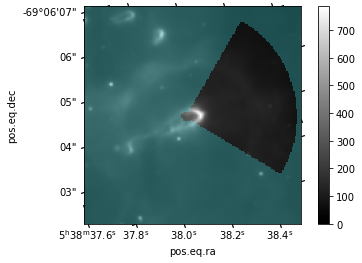

In [40]:
fig = plt.figure()
ax = fig.add_subplot(projection=cutout.wcs)
im = ax.imshow(
    cutout.image,
    vmin=0.0, 
    cmap=cm.neutral,
    )
cb = fig.colorbar(im, ax=ax)
ax.imshow(np.where(cutout.mask, np.nan, 1.0), vmin=0, cmap=cm.gem, alpha=0.3)

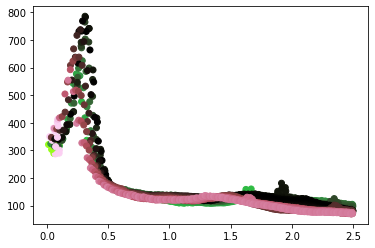

In [41]:
fig, ax = plt.subplots()
m = cutout.mask
ax.scatter(
    cutout.r[m].arcsec, 
    cutout.image[m], 
    c=Angle(cutout.pa - cutout.pa_star).wrap_at(180*u.deg).deg[m], 
    vmin=-60, vmax=60,
    cmap=cm.watermelon)

In [45]:
'''Vis for 3.5 arcsec and cth = 9'''

'Vis for 3.5 arcsec and cth = 9'

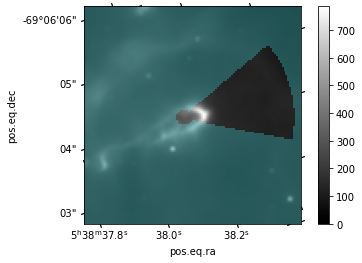

In [46]:
fig = plt.figure()
ax = fig.add_subplot(projection=cutout.wcs)
im = ax.imshow(
    cutout.image,
    vmin=0.0, 
    cmap=cm.neutral,
    )
cb = fig.colorbar(im, ax=ax)
ax.imshow(np.where(cutout.mask, np.nan, 1.0), vmin=0, cmap=cm.gem, alpha=0.3)

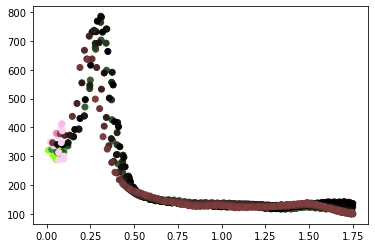

In [47]:
fig, ax = plt.subplots()
m = cutout.mask
ax.scatter(
    cutout.r[m].arcsec, 
    cutout.image[m], 
    c=Angle(cutout.pa - cutout.pa_star).wrap_at(180*u.deg).deg[m], 
    vmin=-60, vmax=60,
    cmap=cm.watermelon)

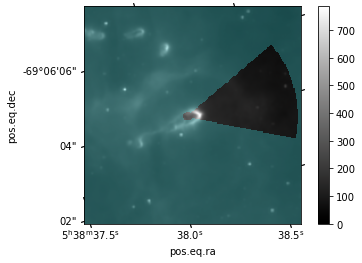

In [49]:
'''Vis for 6 arcsec and cth = 9'''
fig = plt.figure()
ax = fig.add_subplot(projection=cutout.wcs)
im = ax.imshow(
    cutout.image,
    vmin=0.0, 
    cmap=cm.neutral,
    )
cb = fig.colorbar(im, ax=ax)
ax.imshow(np.where(cutout.mask, np.nan, 1.0), vmin=0, cmap=cm.gem, alpha=0.3)

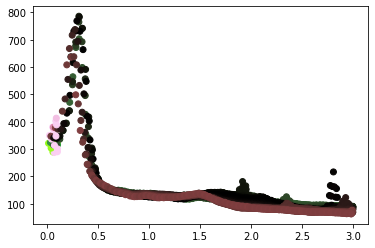

In [51]:
fig, ax = plt.subplots()
m = cutout.mask
ax.scatter(
    cutout.r[m].arcsec, 
    cutout.image[m], 
    c=Angle(cutout.pa - cutout.pa_star).wrap_at(180*u.deg).deg[m], 
    vmin=-60, vmax=60,
    cmap=cm.watermelon)

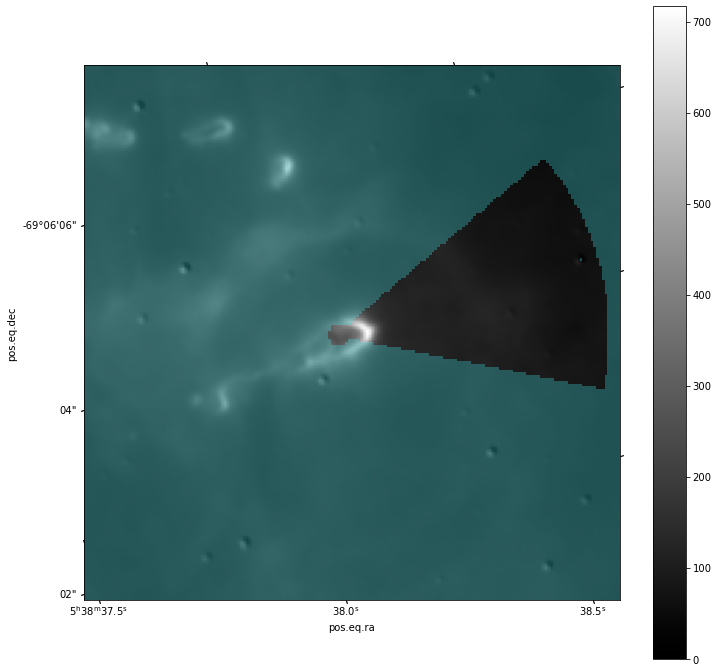

In [86]:
'''Vis for 6 arcsec and cth = 9'''
fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(projection=cutout.wcs)
im = ax.imshow(
    cutout.image,
    vmin=0.0, 
    cmap=cm.neutral,
    )
cb = fig.colorbar(im, ax=ax)
mask = (cutout.mask) & (cutout.mask_stars)
ax.imshow(np.where(mask, np.nan, 1.0), vmin=0, cmap=cm.gem, alpha=0.3)

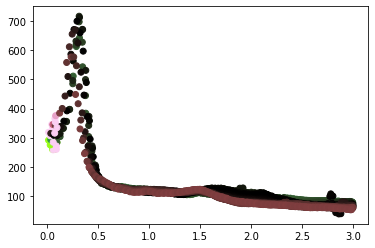

In [87]:
fig, ax = plt.subplots()
m = (cutout.mask) & (cutout.mask_stars)
ax.scatter(
    cutout.r[m].arcsec, 
    cutout.image[m], 
    c=Angle(cutout.pa - cutout.pa_star).wrap_at(180*u.deg).deg[m], 
    vmin=-60, vmax=60,
    cmap=cm.watermelon)

In [82]:
cutout.center

<SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (84.658965, -69.1011375)>